# Avance 3 — Web Scraping de información cultural con Wikipedia y Selenium

**Proyecto integrador M1 — InsightReach**  
**Ciudad principal:** Miami, Florida (Estados Unidos)  
**Segunda ciudad para la práctica de Selenium:** Chicago, Illinois (Estados Unidos)

## Objetivo

En este avance incorporo una dimensión cultural al análisis que desarrollé en los avances anteriores. Para hacerlo, extraigo información pública de Wikipedia sobre la cultura de Miami. En una segunda parte, utilizo Selenium para automatizar la navegación por Wikipedia: ingreso al artículo de Miami, busco Chicago desde el buscador interno, cambio el tema visual y modifico el idioma de la página.

Con esta información complemento los datos de clientes y la oferta gastronómica que obtuve mediante Yelp. Utilizo la información cultural como **contexto cualitativo** para interpretar posibles oportunidades de comunicación y marketing. No la tomo como una descripción de cada cliente ni como un reemplazo de los datos de la encuesta.

## Uso de inteligencia artificial como apoyo

Para desarrollar este avance utilicé una herramienta de inteligencia artificial como apoyo para generar y revisar una primera versión del script. Tomé esa propuesta como punto de partida y organicé el código de acuerdo con las ciudades y las tareas que seleccioné para el proyecto. Antes de dar por terminado el trabajo, ejecuto las celdas, reviso los resultados y compruebo que las evidencias se hayan guardado correctamente. La IA funciona como una herramienta de apoyo; la revisión y la interpretación de los resultados forman parte de mi trabajo.

> **Organización del proyecto:** preparé este notebook como un archivo independiente. De esta manera, puedo incorporar el nuevo avance sin modificar los notebooks ni los resultados que ya tenía de EDA y Yelp.


## 1. Preparación del entorno

Para realizar este avance utilizo `Requests` para descargar la página, `BeautifulSoup` para recorrer su contenido HTML, `Pandas` para organizar los datos y `Selenium` para controlar el navegador.

Trabajo en Google Colab. Instalo las librerías necesarias una vez por sesión. Selenium 4 utiliza Selenium Manager para resolver el controlador del navegador en la mayoría de los entornos compatibles.


In [40]:
%pip -q install requests beautifulsoup4 pandas selenium

## 2. Importación de librerías y configuración

Para mantener la extracción acotada, trabajo con una sola página y una sección temática. También configuro un `User-Agent` descriptivo, siguiendo las recomendaciones de Wikimedia para identificar las solicitudes automatizadas.

Dejo definidas Miami como ciudad principal y Chicago como segunda ciudad para la práctica de Selenium, de modo que el nuevo avance mantenga la continuidad con mi proyecto.


In [41]:
from pathlib import Path
from datetime import datetime, timezone
import os
import re
import sys
import platform
import warnings

import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import display, Markdown, Image

# Fuentes que elegí para mantener la coherencia con mis avances anteriores.
CIUDAD_PRINCIPAL = "Miami"
CIUDAD_SECUNDARIA = "Chicago"
URL_MIAMI = "https://en.wikipedia.org/wiki/Miami"
URL_CHICAGO = "https://en.wikipedia.org/wiki/Chicago"
URL_CHICAGO_ES = "https://es.wikipedia.org/wiki/Chicago"


CONTACTO = "barbaramagdaleno1@gmail.com"
USER_AGENT = (
    "InsightReachWebScraper/1.0 "
    f"(proyecto educativo; contacto: {CONTACTO}) "
    "Python-requests"
)

# Si guardé el proyecto en Google Drive y no se detecta automáticamente,
# escribo aquí la ruta a la carpeta principal del proyecto. Ejemplo:
# DIRECTORIO_PROYECTO = Path('/content/drive/MyDrive/ProyectoM1_NombreEstudiante')
DIRECTORIO_PROYECTO = None


def detectar_carpeta_salida():
    """Busca la carpeta Datos del proyecto sin modificar archivos existentes."""
    candidatos = []
    if DIRECTORIO_PROYECTO is not None:
        candidatos.append(Path(DIRECTORIO_PROYECTO).expanduser() / "Datos")

    actual = Path.cwd().resolve()
    bases = [actual, *list(actual.parents)]
    for base in bases:
        candidatos.extend([
            base / "Datos",
            base / "ProyectoM1_NombreEstudiante" / "Datos",
        ])

    for candidato in candidatos:
        if candidato.is_dir():
            return candidato / "WebScraping"

    # Si ejecuto el notebook fuera de la carpeta del proyecto (por ejemplo, en Colab),
    # guardo los resultados en una carpeta independiente. Luego puedo copiarlos
    # a ProyectoM1_NombreEstudiante/Datos/WebScraping.
    return Path.cwd() / "Resultados_WebScraping"


CARPETA_SALIDA = detectar_carpeta_salida()
CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)
CARPETA_EVIDENCIAS = CARPETA_SALIDA / "evidencias_selenium"
CARPETA_EVIDENCIAS.mkdir(parents=True, exist_ok=True)

if "reemplazar-por-tu-correo" in CONTACTO:
    warnings.warn(
        "Reemplazá CONTACTO por un correo válido antes de ejecutar la extracción, "
        "para identificar el User-Agent ante Wikimedia."
    )

print("Librerías importadas correctamente.")
print(f"Carpeta de resultados: {CARPETA_SALIDA.resolve()}")

Librerías importadas correctamente.
Carpeta de resultados: /content/Resultados_WebScraping


## 3. Descarga responsable de la página de Miami

En esta etapa descargo el artículo público de Miami mediante una petición HTTP. Establezco un tiempo máximo de espera y verifico el código de respuesta para comprobar que la página se haya descargado correctamente. Limito la consulta a esta página y no realizo descargas masivas ni solicitudes en paralelo.


In [42]:
session = requests.Session()
session.headers.update({
    "User-Agent": USER_AGENT,
    "Accept-Language": "en-US,en;q=0.9",
})

respuesta = session.get(URL_MIAMI, timeout=(10, 30))
respuesta.raise_for_status()

print(f"Estado HTTP: {respuesta.status_code}")
print(f"URL final: {respuesta.url}")
print(f"Tamaño descargado: {len(respuesta.content):,} bytes")

soup = BeautifulSoup(respuesta.text, "html.parser")
contenedor = soup.select_one("#mw-content-text .mw-parser-output")

if contenedor is None:
    raise RuntimeError(
        "No se encontró el contenedor principal del artículo. "
        "Wikipedia pudo haber cambiado su estructura HTML."
    )

print("Artículo HTML identificado correctamente.")

Estado HTTP: 200
URL final: https://en.wikipedia.org/wiki/Miami
Tamaño descargado: 1,629,909 bytes
Artículo HTML identificado correctamente.


## 4. Extracción de la sección cultural

Para obtener la información que necesito, localizo el encabezado **Culture** y recopilo los párrafos que aparecen dentro de esa sección, junto con sus subtítulos. Así puedo conservar por separado temas como música, eventos, museos o gastronomía, cuando estén incluidos en el artículo.

Detengo la extracción cuando encuentro la siguiente sección principal del artículo. De esta forma evito incorporar contenido que no corresponde a la sección cultural.


In [43]:
def limpiar_texto(texto):
    """Normaliza espacios y elimina marcas numéricas de referencias [1], [2]..."""
    texto = re.sub(r"\[\s*\d+\s*\]", "", texto)
    texto = re.sub(r"\s+", " ", texto)
    return texto.strip()


elementos = contenedor.find_all(["h2", "h3", "p"])
dentro_de_cultura = False
subseccion_actual = "Introducción de cultura"
filas = []
fecha_extraccion = datetime.now(timezone.utc).isoformat(timespec="seconds")

for elemento in elementos:
    if elemento.name == "h2":
        encabezado = elemento.select_one(".mw-headline")
        titulo = limpiar_texto(encabezado.get_text(" ", strip=True) if encabezado else elemento.get_text(" ", strip=True))
        titulo_normalizado = titulo.lower().replace("[edit]", "").strip()

        if not dentro_de_cultura and titulo_normalizado == "culture":
            dentro_de_cultura = True
            subseccion_actual = "Introducción de cultura"
            continue
        elif dentro_de_cultura:
            # Identifico la siguiente sección de nivel 2 para detener la extracción de Culture.
            break

    elif dentro_de_cultura and elemento.name == "h3":
        encabezado = elemento.select_one(".mw-headline")
        subseccion_actual = limpiar_texto(
            encabezado.get_text(" ", strip=True) if encabezado else elemento.get_text(" ", strip=True)
        )

    elif dentro_de_cultura and elemento.name == "p":
        parrafo = limpiar_texto(elemento.get_text(" ", strip=True))
        if parrafo:
            filas.append({
                "ciudad": CIUDAD_PRINCIPAL,
                "seccion": "Culture",
                "subseccion": subseccion_actual,
                "texto": parrafo,
                "cantidad_palabras": len(parrafo.split()),
                "url_fuente": URL_MIAMI,
                "fecha_extraccion_utc": fecha_extraccion,
            })

if not filas:
    raise RuntimeError(
        "No se encontraron párrafos en la sección Culture. "
        "Revisá si el nombre de la sección o el HTML del artículo cambió."
    )

df_cultura = pd.DataFrame(filas)
print(f"Párrafos culturales extraídos: {len(df_cultura)}")
display(df_cultura.head(10))

Párrafos culturales extraídos: 16


,ciudad,seccion,subseccion,texto,cantidad_palabras,url_fuente,fecha_extraccion_utc
0,Miami,Culture,Introducción de cultura,Miami enjoys a vibrant culture that is influen...,68,https://en.wikipedia.org/wiki/Miami,2026-11-05T04:29:28+00:00
1,Miami,Culture,Introducción de cultura,Miami has been the setting of numerous films a...,155,https://en.wikipedia.org/wiki/Miami,2026-11-05T04:29:28+00:00
2,Miami,Culture,Venues,"Miami is home to many entertainment venues, th...",61,https://en.wikipedia.org/wiki/Miami,2026-11-05T04:29:28+00:00
3,Miami,Culture,Venues,Other performing arts venues in Miami include ...,31,https://en.wikipedia.org/wiki/Miami,2026-11-05T04:29:28+00:00
4,Miami,Culture,Venues,Miami's first boat-in movie theater opened in ...,8,https://en.wikipedia.org/wiki/Miami,2026-11-05T04:29:28+00:00
5,Miami,Culture,Events,"Miami is home to a number of annual festivals,...",29,https://en.wikipedia.org/wiki/Miami,2026-11-05T04:29:28+00:00
6,Miami,Culture,Events,Another celebrated event is the Miami Internat...,43,https://en.wikipedia.org/wiki/Miami,2026-11-05T04:29:28+00:00
7,Miami,Culture,Events,The Miami Jewish Film Festival (MJFF) was esta...,84,https://en.wikipedia.org/wiki/Miami,2026-11-05T04:29:28+00:00
8,Miami,Culture,Events,"Miami is a major fashion center, home to model...",46,https://en.wikipedia.org/wiki/Miami,2026-11-05T04:29:28+00:00
9,Miami,Culture,Music and performing arts,"Miami attracts a large number of musicians, si...",61,https://en.wikipedia.org/wiki/Miami,2026-11-05T04:29:28+00:00


## 5. Resumen y exportación de resultados

Con los párrafos extraídos, preparo una tabla resumen por subsección. También exporto el contenido a archivos CSV y TXT para poder revisarlo y reutilizarlo en el proyecto.

Guardo los archivos dentro de `Datos/WebScraping/` cuando el notebook detecta la estructura original de mi proyecto. Si ejecuto el notebook fuera de esa carpeta, creo `Resultados_WebScraping/` en el directorio de trabajo.


In [44]:
resumen_cultura = (
    df_cultura.groupby("subseccion", dropna=False)
    .agg(
        cantidad_parrafos=("texto", "count"),
        total_palabras=("cantidad_palabras", "sum"),
    )
    .reset_index()
    .sort_values("total_palabras", ascending=False)
)

ruta_csv = CARPETA_SALIDA / "cultura_miami_wikipedia.csv"
ruta_resumen = CARPETA_SALIDA / "resumen_cultura_miami.csv"
ruta_txt = CARPETA_SALIDA / "cultura_miami_wikipedia.txt"

# Uso UTF-8-SIG para facilitar la apertura del CSV en Excel.
df_cultura.to_csv(ruta_csv, index=False, encoding="utf-8-sig")
resumen_cultura.to_csv(ruta_resumen, index=False, encoding="utf-8-sig")

with open(ruta_txt, "w", encoding="utf-8") as archivo:
    archivo.write("EXTRACCIÓN CULTURAL DE MIAMI — WIKIPEDIA\n")
    archivo.write(f"Fecha de extracción (UTC): {fecha_extraccion}\n")
    archivo.write(f"Fuente: {URL_MIAMI}\n")
    archivo.write("Atribución: Wikipedia contributors, artículo ‘Miami’.\n")
    archivo.write("Licencia del texto: Creative Commons Attribution-ShareAlike 4.0 (CC BY-SA 4.0), según los términos aplicables de Wikimedia.\n")
    archivo.write("=" * 80 + "\n\n")
    for _, fila in df_cultura.iterrows():
        archivo.write(f"[{fila['subseccion']}]\n{fila['texto']}\n\n")

print("Archivos exportados:")
print(ruta_csv.resolve())
print(ruta_resumen.resolve())
print(ruta_txt.resolve())

display(resumen_cultura)

Archivos exportados:
/content/Resultados_WebScraping/cultura_miami_wikipedia.csv
/content/Resultados_WebScraping/resumen_cultura_miami.csv
/content/Resultados_WebScraping/cultura_miami_wikipedia.txt


,subseccion,cantidad_parrafos,total_palabras
1,Dialect,3,225
3,Introducción de cultura,2,223
0,Cuisine,2,207
2,Events,4,202
6,Venues,3,100
4,Museums and visual arts,1,61
5,Music and performing arts,1,61


## 6. Lectura del resultado y relación con mi proyecto

Al revisar la tabla resumen puedo identificar qué subsecciones del artículo contienen más texto. El archivo CSV conserva cada párrafo y su subtítulo, lo que me facilita consultar el contenido con más detalle.

**Cómo integro esta fuente con los avances anteriores:**

- Con la base de clientes analicé las preferencias y los comportamientos declarados por las personas encuestadas.
- Con Yelp obtuve información sobre la oferta de restaurantes y sus categorías.
- Con Wikipedia incorporo contexto cualitativo sobre la cultura de Miami.

Esta tercera fuente me puede ayudar a plantear ideas para futuras campañas, por ejemplo, explorar contenidos relacionados con gastronomía, música o eventos locales. Sin embargo, no la utilizo para afirmar que todos los residentes comparten las mismas preferencias ni para estimar la demanda de un segmento. Como Wikipedia es una fuente secundaria y colaborativa, interpreto su contenido como contexto y no como una medición estadística de la población.


## 7. Automatización de navegación con Selenium

En esta parte utilizo Selenium para realizar los pasos adicionales de la consigna:

1. Abro el artículo de Miami.
2. Utilizo el buscador interno de Wikipedia para buscar Chicago.
3. Cambio el tema visual al modo opuesto al que detecto inicialmente: oscuro o claro.
4. Cambio el idioma de la página a español.

Incorporo esperas explícitas para sincronizar mis acciones con la carga de la página. Además, guardo capturas de pantalla como evidencia del recorrido. En Google Colab el navegador suele ejecutarse en modo *headless*, por lo que puedo revisar las capturas como imágenes al final del notebook.


In [45]:
import shutil
import subprocess
import selenium
import sys

print("VERSIÓN DE PYTHON:", sys.version)
print("VERSIÓN DE SELENIUM:", selenium.__version__)

for nombre in ["google-chrome", "chromium",
               "chromium-browser", "chromedriver"]:
    ruta = shutil.which(nombre)
    print(f"\n{nombre}: {ruta}")

    if ruta:
        resultado = subprocess.run(
            [ruta, "--version"],
            capture_output=True,
            text=True
        )
        print(resultado.stdout or resultado.stderr)

VERSIÓN DE PYTHON: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
VERSIÓN DE SELENIUM: 4.52.0

google-chrome: /usr/bin/google-chrome
Google Chrome 157.0.8103.38 


chromium: None

chromium-browser: None

chromedriver: None


In [46]:
# Instalo Google Chrome dentro del entorno de Colab

!apt-get update -qq
!apt-get install -y -qq wget

!wget -q https://dl.google.com/linux/direct/google-chrome-stable_current_amd64.deb \
    -O /tmp/google-chrome.deb

!apt-get install -y -qq /tmp/google-chrome.deb

# Compruebo la instalación
!google-chrome --version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Google Chrome 157.0.8103.38 


In [47]:
from selenium import webdriver
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

# Configuro Chrome para Google Colab
options = webdriver.ChromeOptions()

options.binary_location = "/usr/bin/google-chrome"

options.add_argument("--headless=new")
options.add_argument("--no-sandbox")
options.add_argument("--disable-dev-shm-usage")
options.add_argument("--disable-gpu")
options.add_argument("--window-size=1440,1000")

# Selenium Manager buscará el controlador compatible
driver = webdriver.Chrome(options=options)

driver.set_page_load_timeout(60)
wait = WebDriverWait(driver, 20)

print("¡Navegador iniciado correctamente!")
print("Modo headless:", True)

¡Navegador iniciado correctamente!
Modo headless: True


In [48]:
from pathlib import Path
from IPython.display import display, Image as IPyImage

# Creo una carpeta para guardar las capturas
CARPETA_EVIDENCIAS = Path("evidencias_webscraping")
CARPETA_EVIDENCIAS.mkdir(exist_ok=True)

# Función para guardar y mostrar capturas del navegador
def guardar_captura(nombre_archivo, descripcion=""):
    ruta = CARPETA_EVIDENCIAS / nombre_archivo

    driver.save_screenshot(str(ruta))

    print(f"Captura guardada: {ruta}")

    if descripcion:
        print("Descripción:", descripcion)

    display(IPyImage(filename=str(ruta)))

    return ruta

print("Función de captura configurada correctamente.")

Función de captura configurada correctamente.


### 7.1. Abrir Miami y buscar Chicago con el buscador interno

Primero abro el artículo de Miami. Después localizo el campo de búsqueda interno de Wikipedia, escribo `Chicago` y envío la consulta con la tecla Enter. Finalmente verifico que el artículo cargado corresponda a la ciudad que busqué.


Página inicial: Miami - Wikipedia
Captura guardada: evidencias_webscraping/01_miami_inicio.png
Descripción: Apertura del artículo de Miami


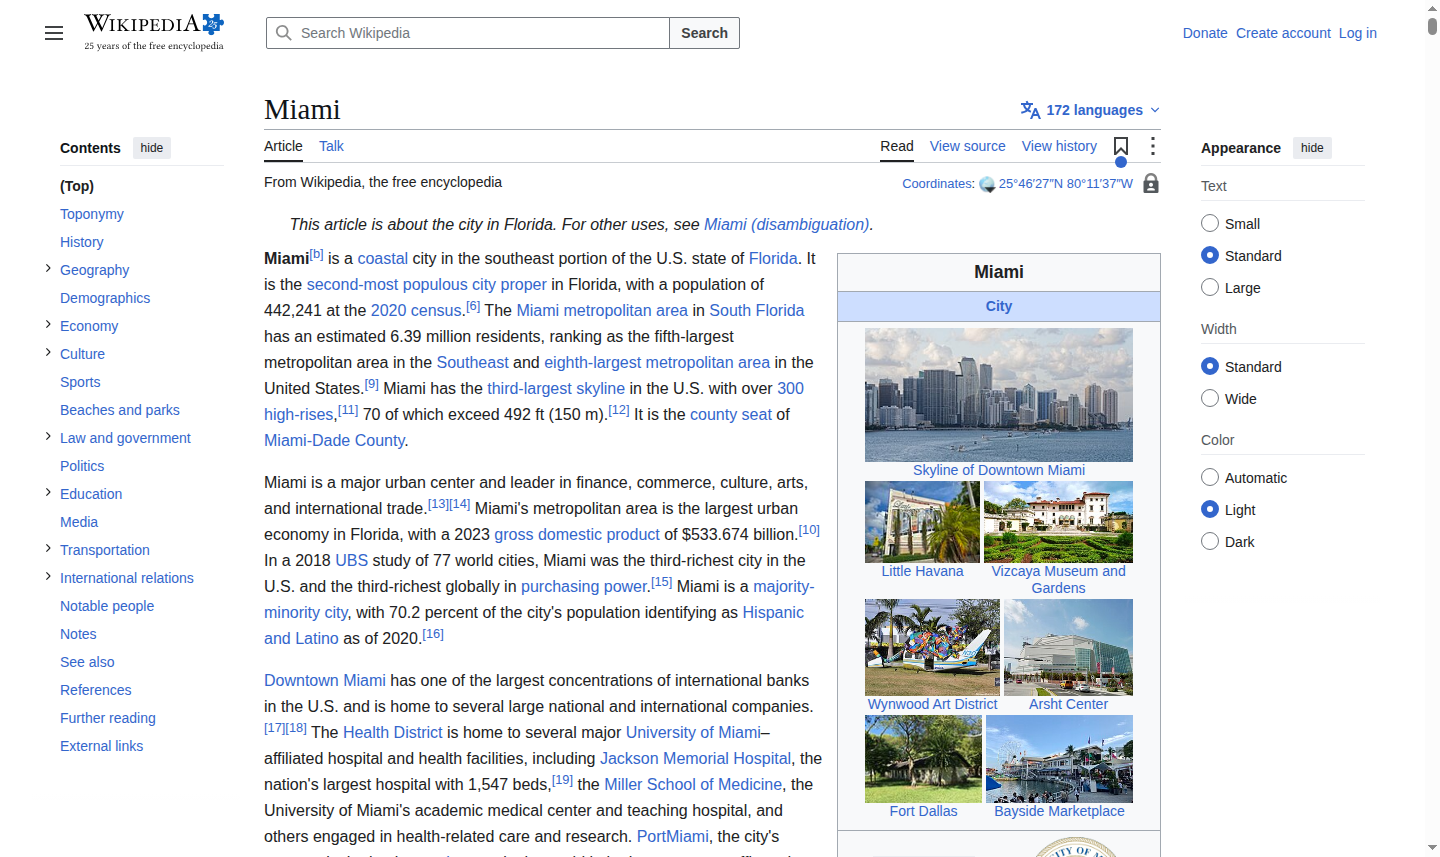

Wikipedia actualizó el buscador. Reintentando...
Búsqueda interna completada: Chicago
Captura guardada: evidencias_webscraping/02_chicago_busqueda.png
Descripción: Búsqueda interna de Chicago desde Miami


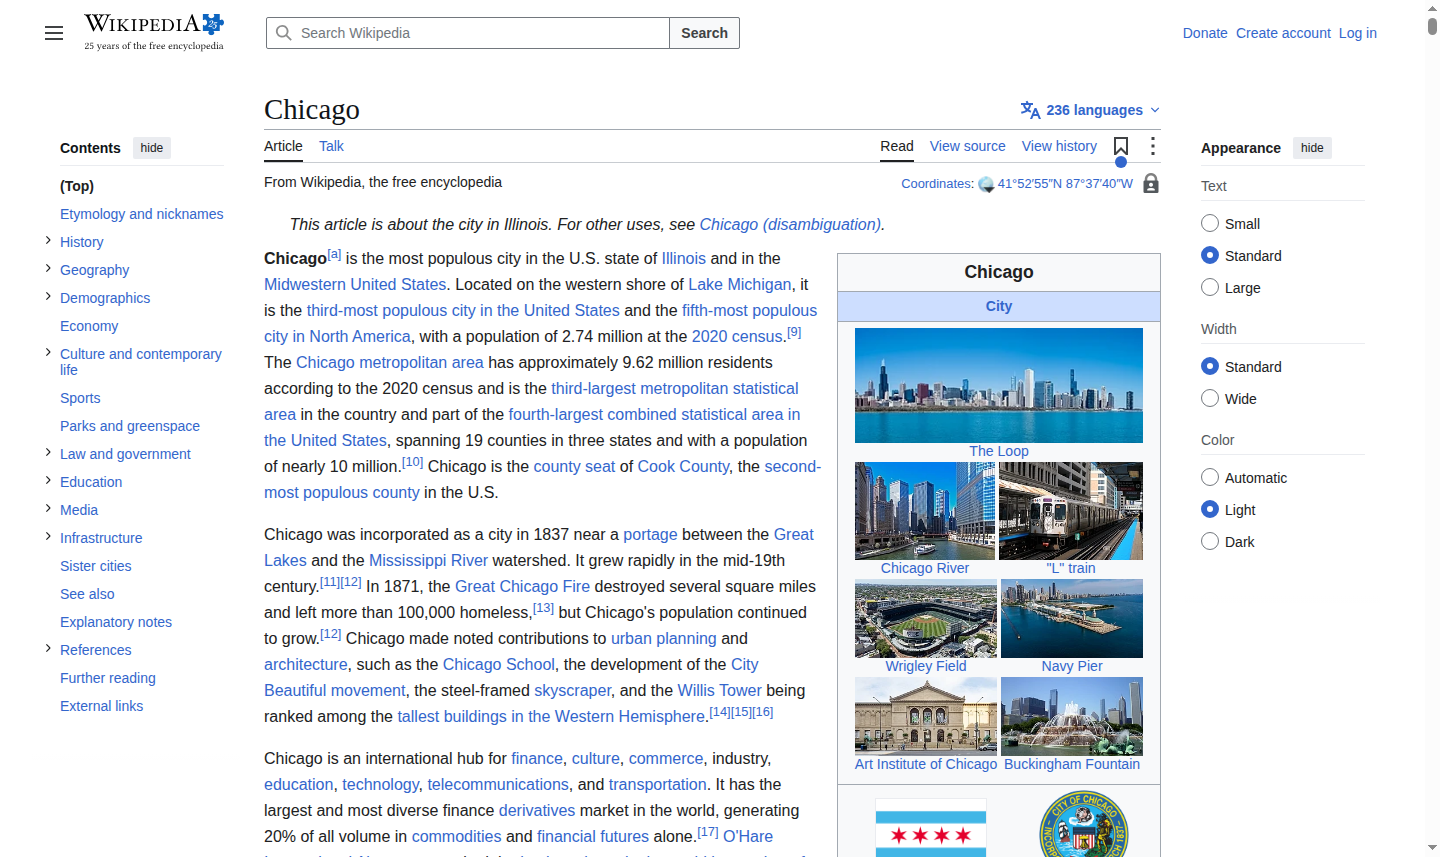

PosixPath('evidencias_webscraping/02_chicago_busqueda.png')

In [49]:

from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.support import expected_conditions as EC
from selenium.common.exceptions import StaleElementReferenceException
import time

# 1. Abro el artículo de Miami
driver.get(URL_MIAMI)

wait.until(EC.presence_of_element_located((By.ID, "firstHeading")))

print("Página inicial:", driver.title)

guardar_captura(
    "01_miami_inicio.png",
    "Apertura del artículo de Miami"
)

# 2. Busco el campo de búsqueda visible
def buscar_campo(d):
    elementos = d.find_elements(
        By.CSS_SELECTOR,
        "input#searchInput, input[name='search']"
    )
    for elemento in elementos:
        if elemento.is_displayed() and elemento.is_enabled():
            return elemento
    return False

# 3. Interactúo con el buscador, volviendo a localizarlo
# si Wikipedia actualiza el elemento
for intento in range(3):
    try:
        campo = wait.until(buscar_campo)
        campo.click()

        campo = wait.until(buscar_campo)
        campo.send_keys(Keys.CONTROL, "a")

        campo = wait.until(buscar_campo)
        campo.send_keys(CIUDAD_SECUNDARIA)

        campo = wait.until(buscar_campo)
        campo.send_keys(Keys.ENTER)

        break

    except StaleElementReferenceException:
        if intento == 2:
            raise
        print("Wikipedia actualizó el buscador. Reintentando...")
        time.sleep(1)

# 4. Espero a que abra el artículo de Chicago
wait.until(
    lambda d: "/wiki/chicago" in d.current_url.lower()
    and "special:search" not in d.current_url.lower()
)

encabezado_chicago = wait.until(
    EC.visibility_of_element_located(
        (By.ID, "firstHeading")
    )
).text

if "chicago" not in encabezado_chicago.lower():
    raise RuntimeError(
        f"No se encontró el artículo esperado: {encabezado_chicago}"
    )

print("Búsqueda interna completada:", encabezado_chicago)

guardar_captura(
    "02_chicago_busqueda.png",
    "Búsqueda interna de Chicago desde Miami"
)


### 7.2. Cambiar el tema de visualización

Después de ingresar al artículo de Chicago, detecto si la página está en modo claro u oscuro y selecciono el modo opuesto. Primero intento utilizar los controles de apariencia de Wikipedia (opciones `vector-theme`).

También verifico que el tema haya cambiado. Si Wikipedia modifica su interfaz y los controles dejan de estar disponibles, el código informa el problema para que pueda revisar el paso y completarlo manualmente. No considero exitoso el cambio si no puedo comprobarlo.


Tema detectado: day
Tema solicitado: night
¡Cambio de tema realizado correctamente!
Tema final: night
Captura guardada: evidencias_webscraping/03_chicago_tema_cambiado.png
Descripción: Wikipedia Chicago con tema night


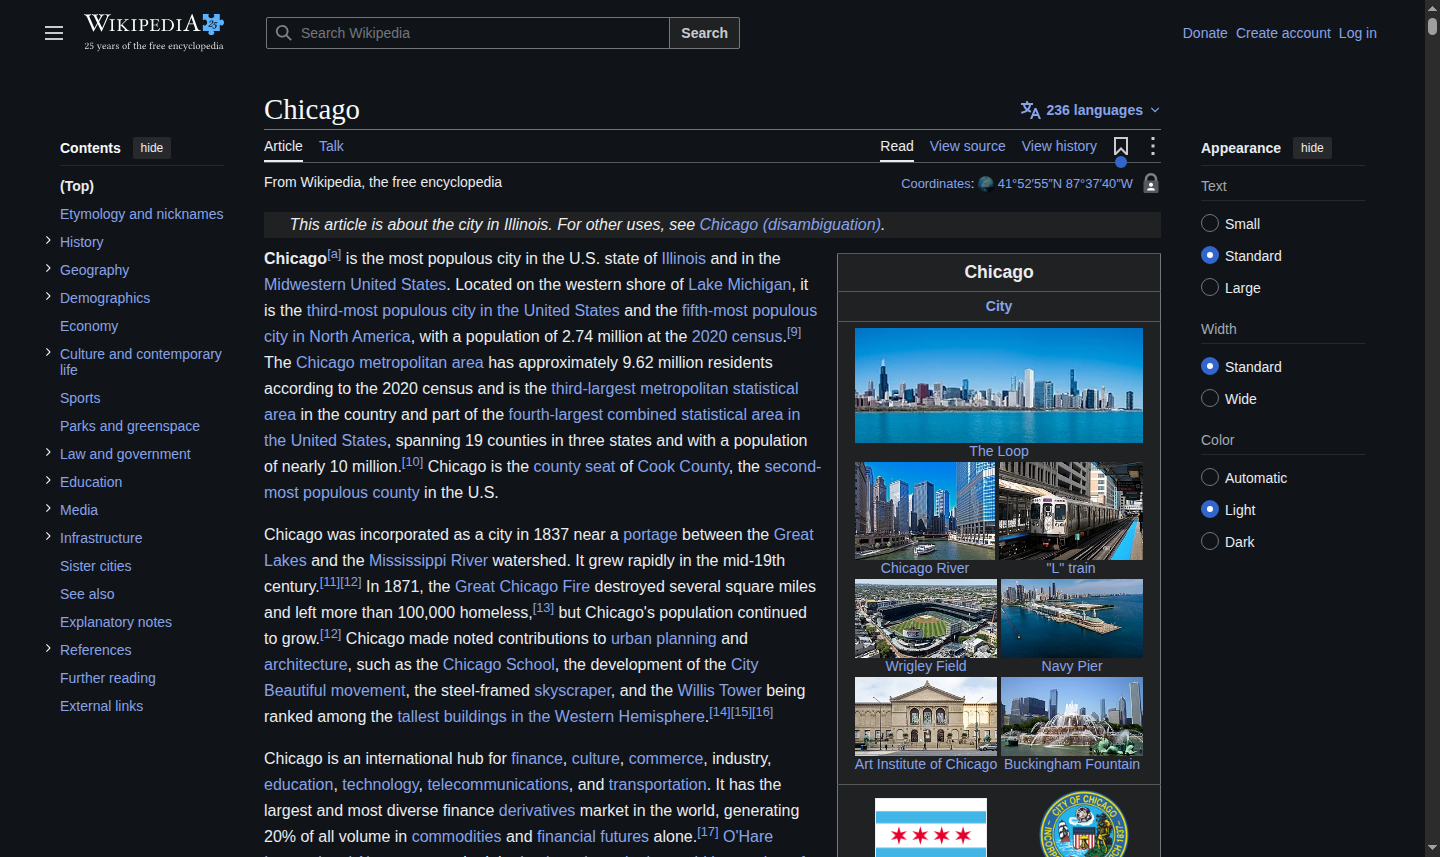

PosixPath('evidencias_webscraping/03_chicago_tema_cambiado.png')

In [50]:

# 7.2. Cambio el tema de visualización de Wikipedia

# Primero identifico el tema actual
clases_html = driver.find_element(
    By.TAG_NAME, "html"
).get_attribute("class")

if "skin-theme-clientpref-night" in clases_html:
    tema_inicial = "night"
elif "skin-theme-clientpref-day" in clases_html:
    tema_inicial = "day"
else:
    tema_inicial = "os"

print("Tema detectado:", tema_inicial)

# Selecciono el tema contrario al actual
if tema_inicial == "night":
    tema_objetivo = "day"
elif tema_inicial == "day":
    tema_objetivo = "night"
else:
    sistema_oscuro = driver.execute_script(
        "return window.matchMedia('(prefers-color-scheme: dark)').matches"
    )
    tema_objetivo = "day" if sistema_oscuro else "night"

print("Tema solicitado:", tema_objetivo)

# Utilizo la función oficial de preferencias de Wikimedia
resultado_tema = driver.execute_async_script("""
    const tema = arguments[0];
    const finalizar = arguments[arguments.length - 1];

    mw.loader.using('mediawiki.user').then(() => {

        if (!mw.user.clientPrefs ||
            typeof mw.user.clientPrefs.set !== 'function') {
            finalizar({
                ok: false,
                mensaje: 'La función de preferencias no está disponible'
            });
            return;
        }

        mw.user.clientPrefs.set('skin-theme', tema);

        setTimeout(() => {
            const clases = document.documentElement.className;
            const correcto = clases.includes(
                'skin-theme-clientpref-' + tema
            );

            finalizar({
                ok: correcto,
                tema: tema,
                clases: clases
            });
        }, 800);

    }).catch(error => {
        finalizar({
            ok: false,
            mensaje: error.message
        });
    });
""", tema_objetivo)

if not resultado_tema["ok"]:
    raise RuntimeError(
        f"No se pudo cambiar el tema: {resultado_tema}"
    )

print("¡Cambio de tema realizado correctamente!")
print("Tema final:", tema_objetivo)

# Guardo la evidencia
guardar_captura(
    "03_chicago_tema_cambiado.png",
    f"Wikipedia Chicago con tema {tema_objetivo}"
)


### 7.3. Cambiar el idioma de la página a español

Por último, busco el enlace de Wikipedia en español correspondiente al artículo de Chicago. Si ese enlace no está visible, intento abrir el selector de idiomas y elegir `Español`.

Compruebo el cambio verificando que la dirección final pertenezca a `es.wikipedia.org`. Así puedo confirmar que la página quedó en un idioma diferente del inglés, que es el idioma predeterminado que utilicé al iniciar la navegación.


Idioma cambiado y verificado: https://es.wikipedia.org/wiki/Chicago
Título en español: Chicago
Captura guardada: evidencias_webscraping/04_chicago_idioma_espanol.png
Descripción: Cambio de idioma de Chicago a español


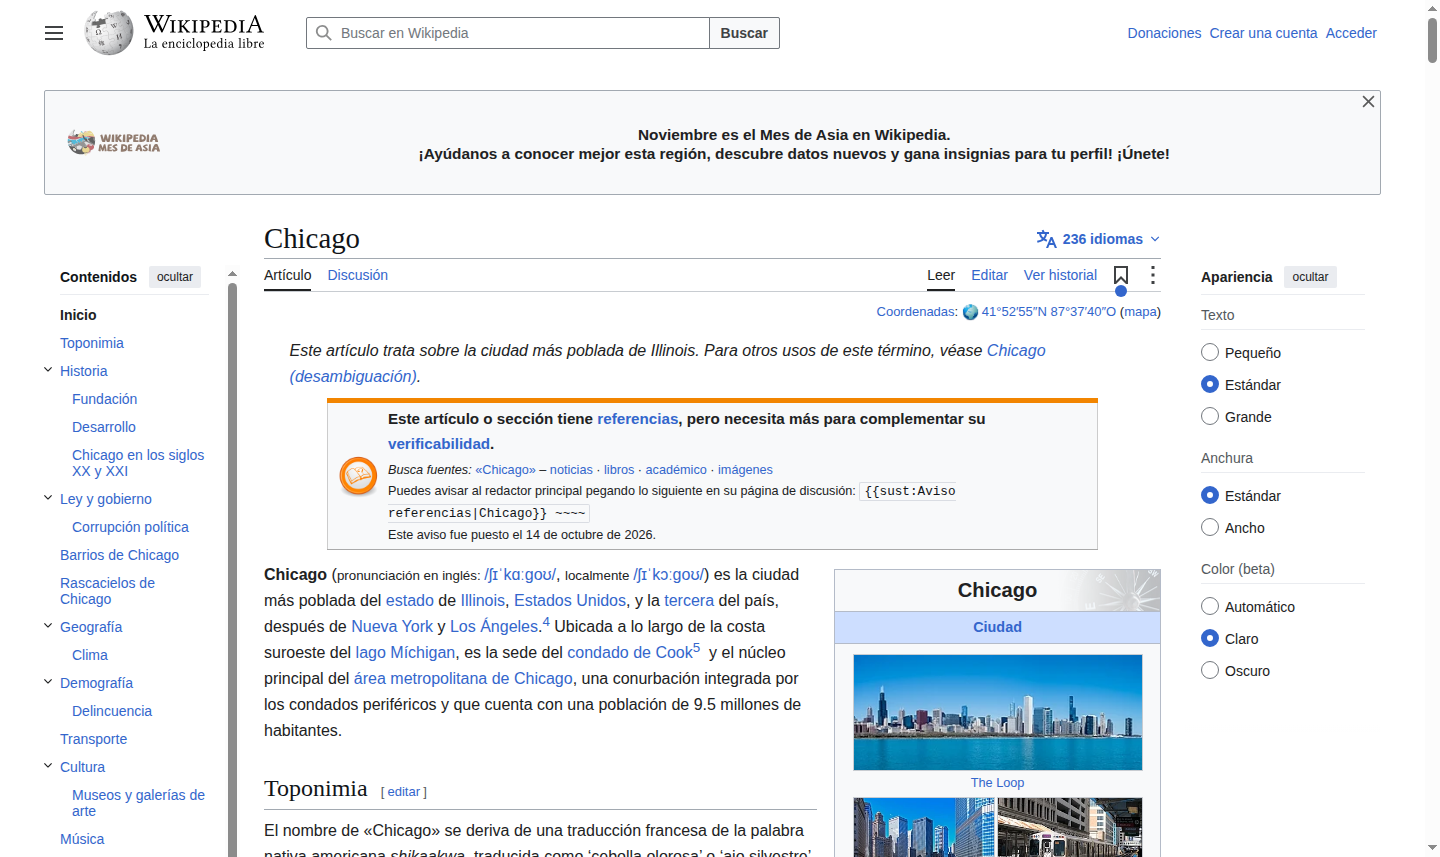

PosixPath('evidencias_webscraping/04_chicago_idioma_espanol.png')

In [51]:
def buscar_enlace_espanol():
    selectores = [
        "a[hreflang='es']",
        "a[lang='es']",
        "#p-lang a[href*='es.wikipedia.org']",
        "a[href*='es.wikipedia.org/wiki/Chicago']",
    ]
    for selector in selectores:
        for enlace in driver.find_elements(By.CSS_SELECTOR, selector):
            href = enlace.get_attribute("href") or ""
            if "es.wikipedia.org" in href and "Chicago" in href:
                return enlace
    return None


enlace_es = buscar_enlace_espanol()
if enlace_es is not None:
    try:
        driver.execute_script("arguments[0].scrollIntoView({block: 'center'});", enlace_es)
        enlace_es.click()
    except WebDriverException:
        driver.get(URL_CHICAGO_ES)
else:
    # Como alternativa, abro el selector de idioma y busco la opción Español.
    boton_idioma = None
    selectores_idioma = [
        "#p-lang-btn",
        "button[aria-label*='Language']",
        "button[title*='Language']",
        "button[aria-label*='idioma']",
    ]
    for selector in selectores_idioma:
        candidatos = driver.find_elements(By.CSS_SELECTOR, selector)
        boton_idioma = next((e for e in candidatos if e.is_displayed()), None)
        if boton_idioma is not None:
            break

    if boton_idioma is not None:
        boton_idioma.click()
        posibles_busquedas = driver.find_elements(
            By.CSS_SELECTOR,
            "input#searchLanguage, input[placeholder*='Search'], input[placeholder*='Buscar']"
        )
        campo_idioma = next((e for e in posibles_busquedas if e.is_displayed()), None)
        if campo_idioma is not None:
            campo_idioma.send_keys("Español")
        opciones_es = driver.find_elements(
            By.XPATH,
            "//*[self::a or self::button or @role='option'][contains(translate(normalize-space(.),'ESPAÑOL','español'),'español')]"
        )
        opcion_visible = next((e for e in opciones_es if e.is_displayed()), None)
        if opcion_visible is not None:
            opcion_visible.click()
        else:
            driver.get(URL_CHICAGO_ES)
    else:
        # Uso este último recurso si Wikipedia cambia
        # la implementación de su selector de idiomas.
        driver.get(URL_CHICAGO_ES)

wait.until(lambda d: "es.wikipedia.org" in d.current_url)
wait.until(EC.presence_of_element_located((By.ID, "firstHeading")))
print("Idioma cambiado y verificado:", driver.current_url)
print("Título en español:", driver.find_element(By.ID, "firstHeading").text)
guardar_captura("04_chicago_idioma_espanol.png", "Cambio de idioma de Chicago a español")

Verificación del tema: {'claseOscura': True, 'guardado': True, 'tema': 'night'}
¡Tema oscuro aplicado y verificado!
Captura guardada: evidencias_webscraping/05_chicago_tema_oscuro_verificado.png


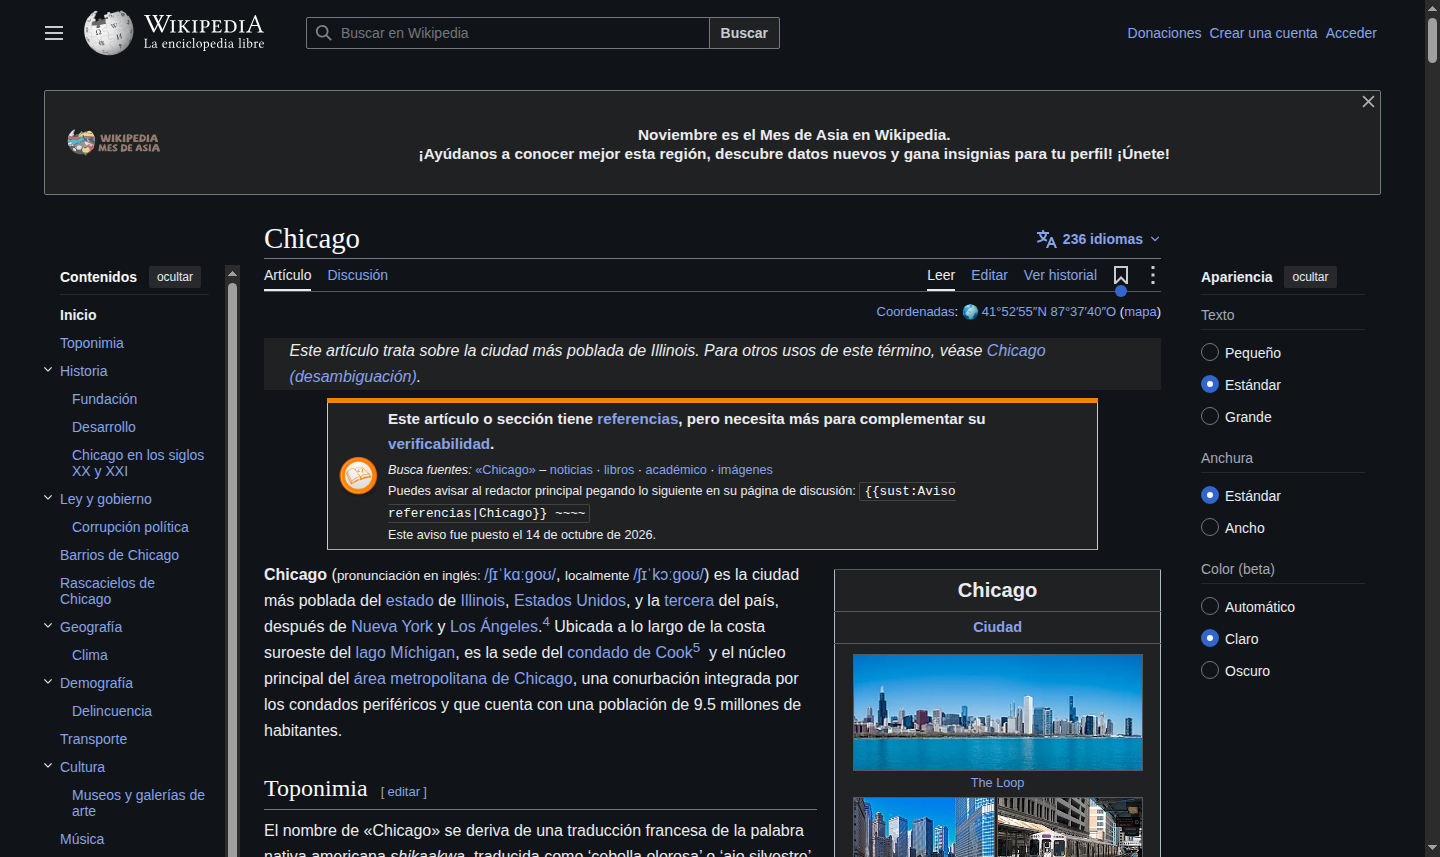

Navegador de verificación cerrado.


In [53]:

from selenium import webdriver
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.common.by import By
from pathlib import Path
from IPython.display import display, Image as IPyImage

# Inicio un navegador nuevo
options = webdriver.ChromeOptions()
options.binary_location = "/usr/bin/google-chrome"
options.add_argument("--headless=new")
options.add_argument("--no-sandbox")
options.add_argument("--disable-dev-shm-usage")
options.add_argument("--disable-gpu")
options.add_argument("--window-size=1440,1000")

driver_tema = webdriver.Chrome(options=options)

try:
    wait_tema = WebDriverWait(driver_tema, 20)

    # Abro Chicago en español
    driver_tema.get("https://es.wikipedia.org/wiki/Chicago")

    wait_tema.until(
        lambda d: "es.wikipedia.org" in d.current_url
    )

    # Cambio la preferencia oficial de Wikipedia a oscuro
    resultado = driver_tema.execute_async_script("""
        const terminar = arguments[arguments.length - 1];

        mw.loader.using('mediawiki.user').then(() => {
            const preferencias = mw.user.clientPrefs;
            const guardado = preferencias.set('skin-theme', 'night');

            setTimeout(() => {
                terminar({
                    guardado: guardado,
                    tema: preferencias.get('skin-theme'),
                    claseOscura: document.documentElement.classList
                        .contains('skin-theme-clientpref-night')
                });
            }, 800);

        }).catch(error => terminar({error: error.message}));
    """)

    print("Verificación del tema:", resultado)

    if not resultado.get("guardado") or not resultado.get("claseOscura"):
        raise RuntimeError("No se pudo confirmar el tema oscuro.")

    print("¡Tema oscuro aplicado y verificado!")

    # Guardo la evidencia
    carpeta = Path("evidencias_webscraping")
    carpeta.mkdir(exist_ok=True)

    ruta = carpeta / "05_chicago_tema_oscuro_verificado.png"

    driver_tema.save_screenshot(str(ruta))

    print("Captura guardada:", ruta)

    display(IPyImage(filename=str(ruta)))

finally:
    driver_tema.quit()
    print("Navegador de verificación cerrado.")


## 8. Guardado de evidencias y cierre del navegador

Al terminar la navegación, guardo capturas de pantalla de los pasos realizados. También preparo un archivo CSV con el registro de evidencias: acción, URL final, título de la página, ruta de la captura y fecha de ejecución.

Reviso las imágenes y el registro para comprobar qué pasos se completaron. Al finalizar, cierro el navegador para liberar los recursos utilizados por Selenium.


REGISTRO DE EVIDENCIAS


,archivo,descripcion,ruta
0,01_miami_inicio.png,Apertura del artículo de Miami,evidencias_webscraping/01_miami_inicio.png
1,02_chicago_busqueda.png,Búsqueda interna de Chicago,evidencias_webscraping/02_chicago_busqueda.png
2,03_chicago_tema_cambiado.png,Cambio de tema de Wikipedia,evidencias_webscraping/03_chicago_tema_cambiad...
3,04_chicago_idioma_espanol.png,Cambio de idioma de Wikipedia,evidencias_webscraping/04_chicago_idioma_espan...
4,05_chicago_tema_oscuro_verificado.png,Cambio de tema de Wikipedia,evidencias_webscraping/05_chicago_tema_oscuro_...



Cantidad de capturas: 5
Archivo CSV: /content/Resultados_WebScraping/evidencias_selenium.csv

 01_miami_inicio.png


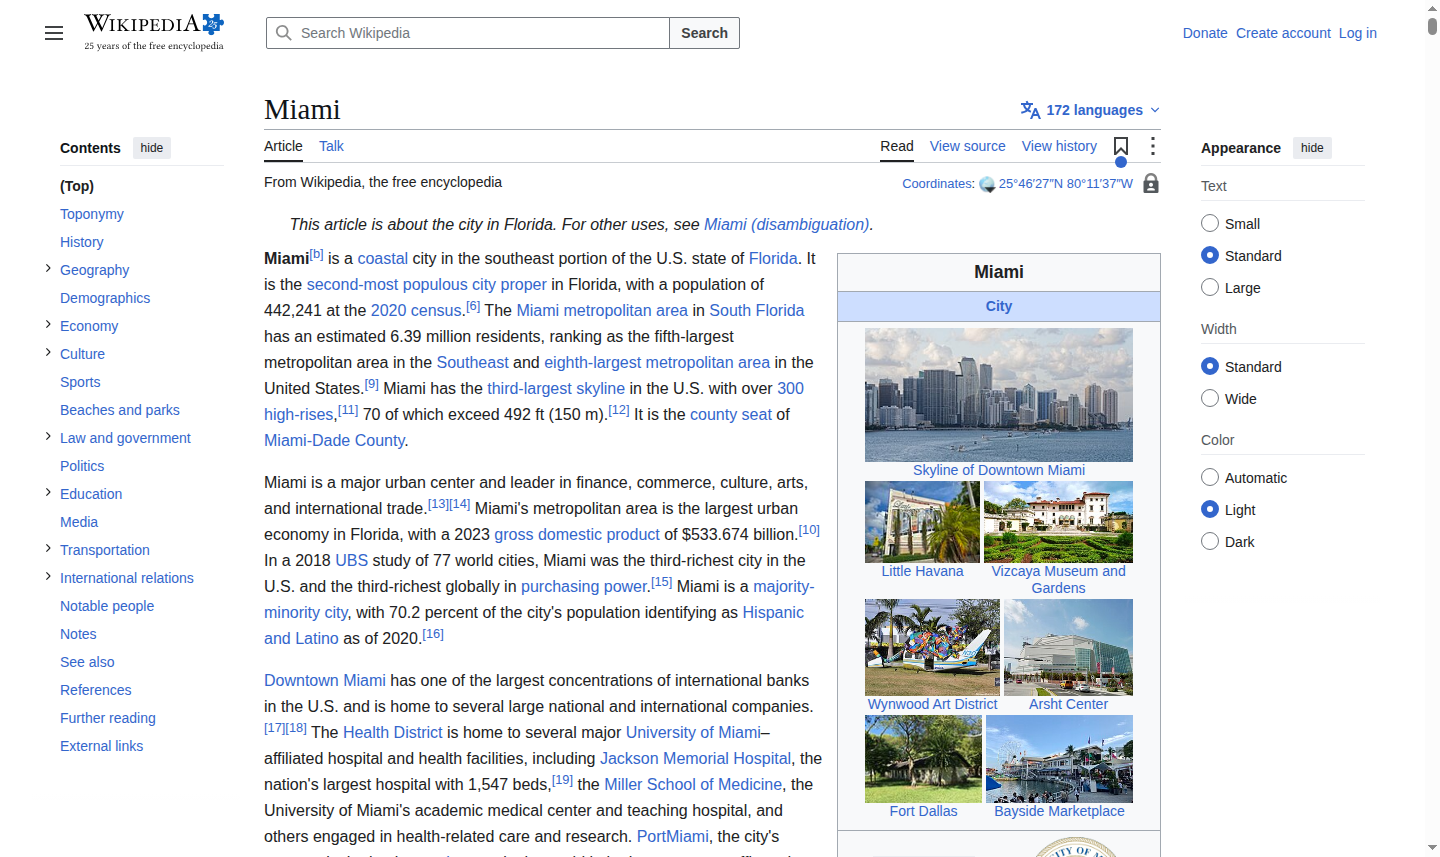


 02_chicago_busqueda.png


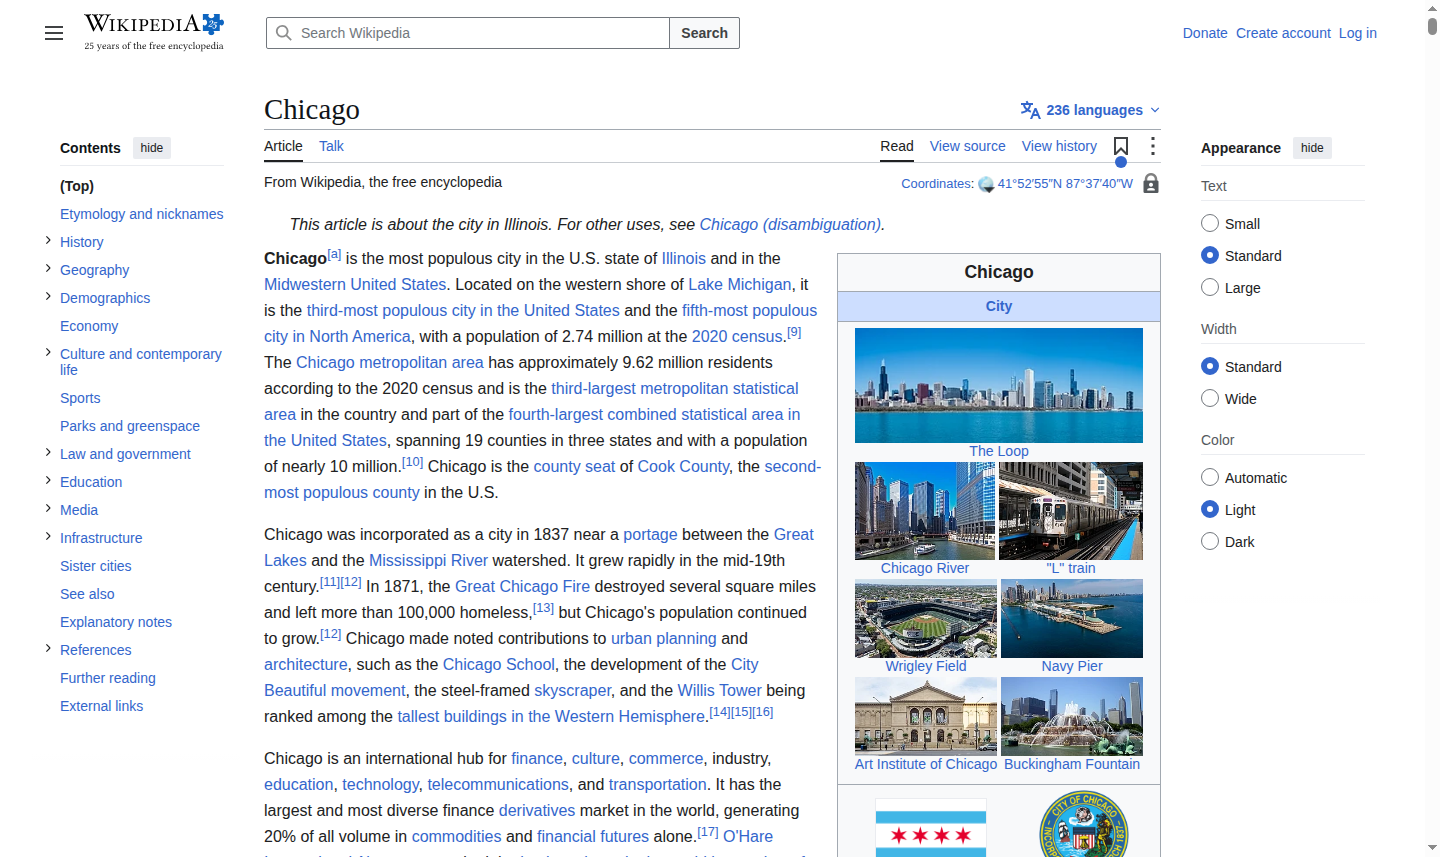


 03_chicago_tema_cambiado.png


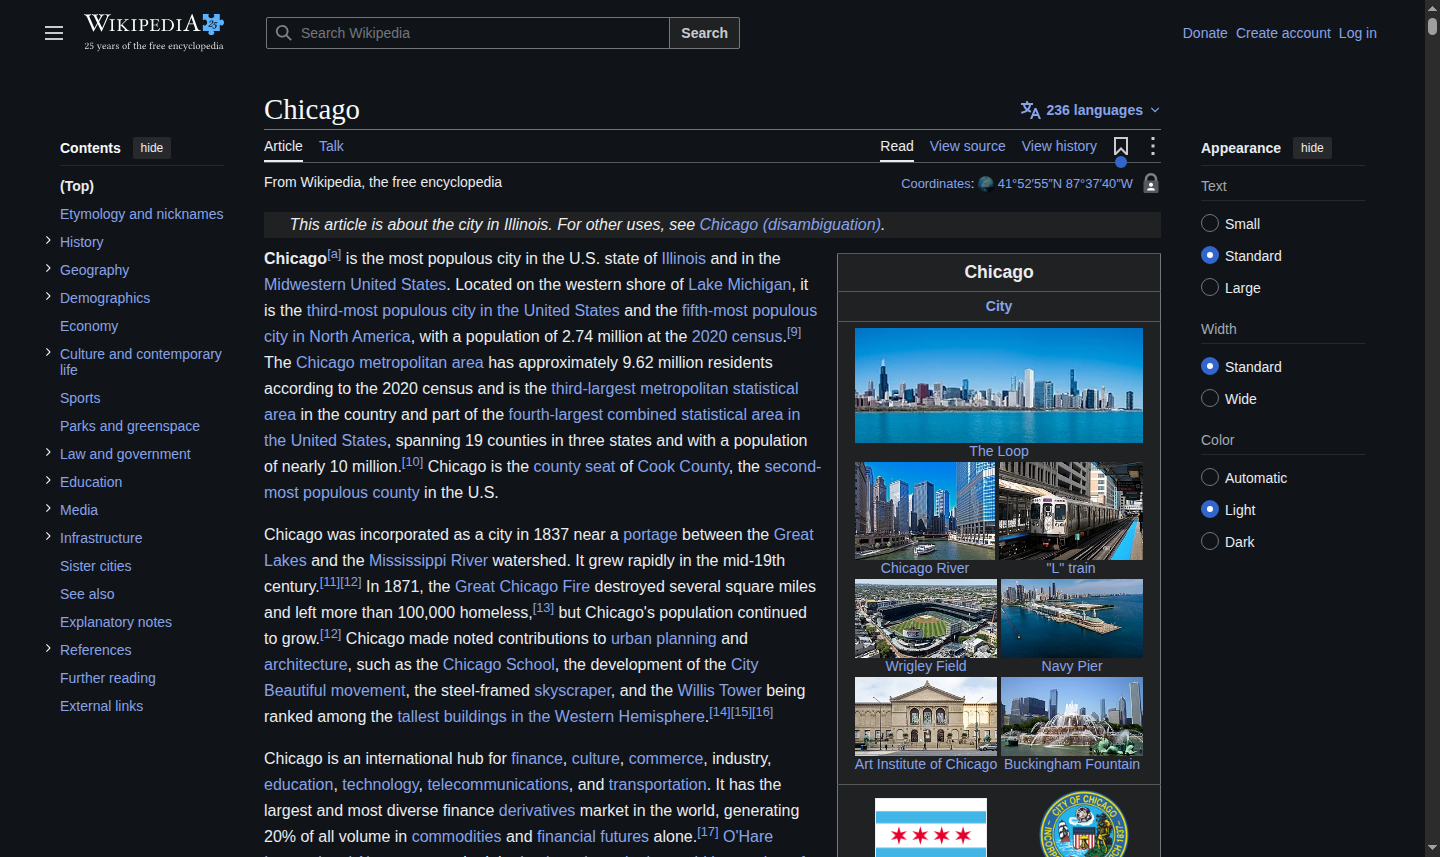


 04_chicago_idioma_espanol.png


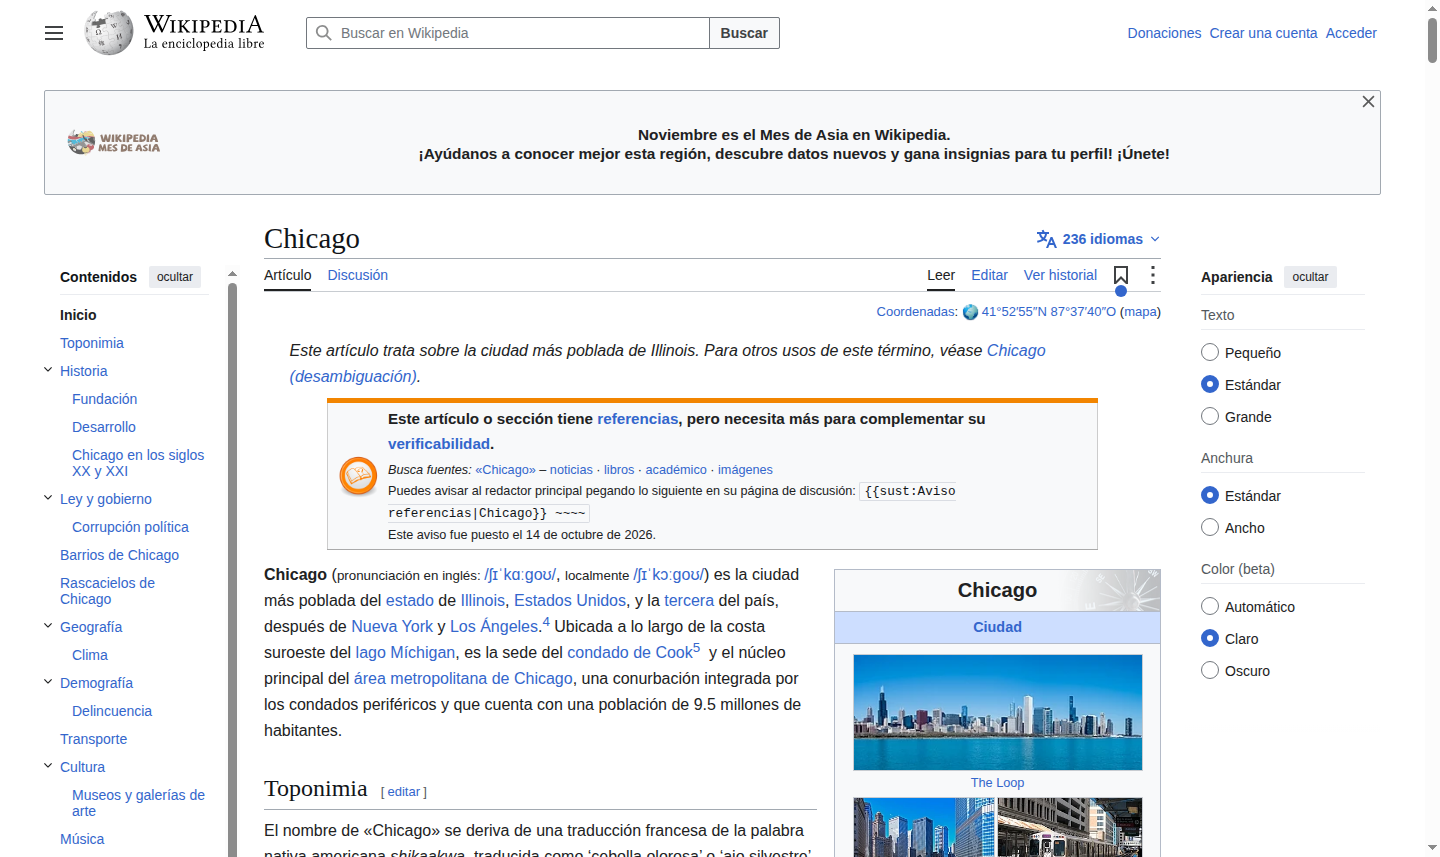


 05_chicago_tema_oscuro_verificado.png


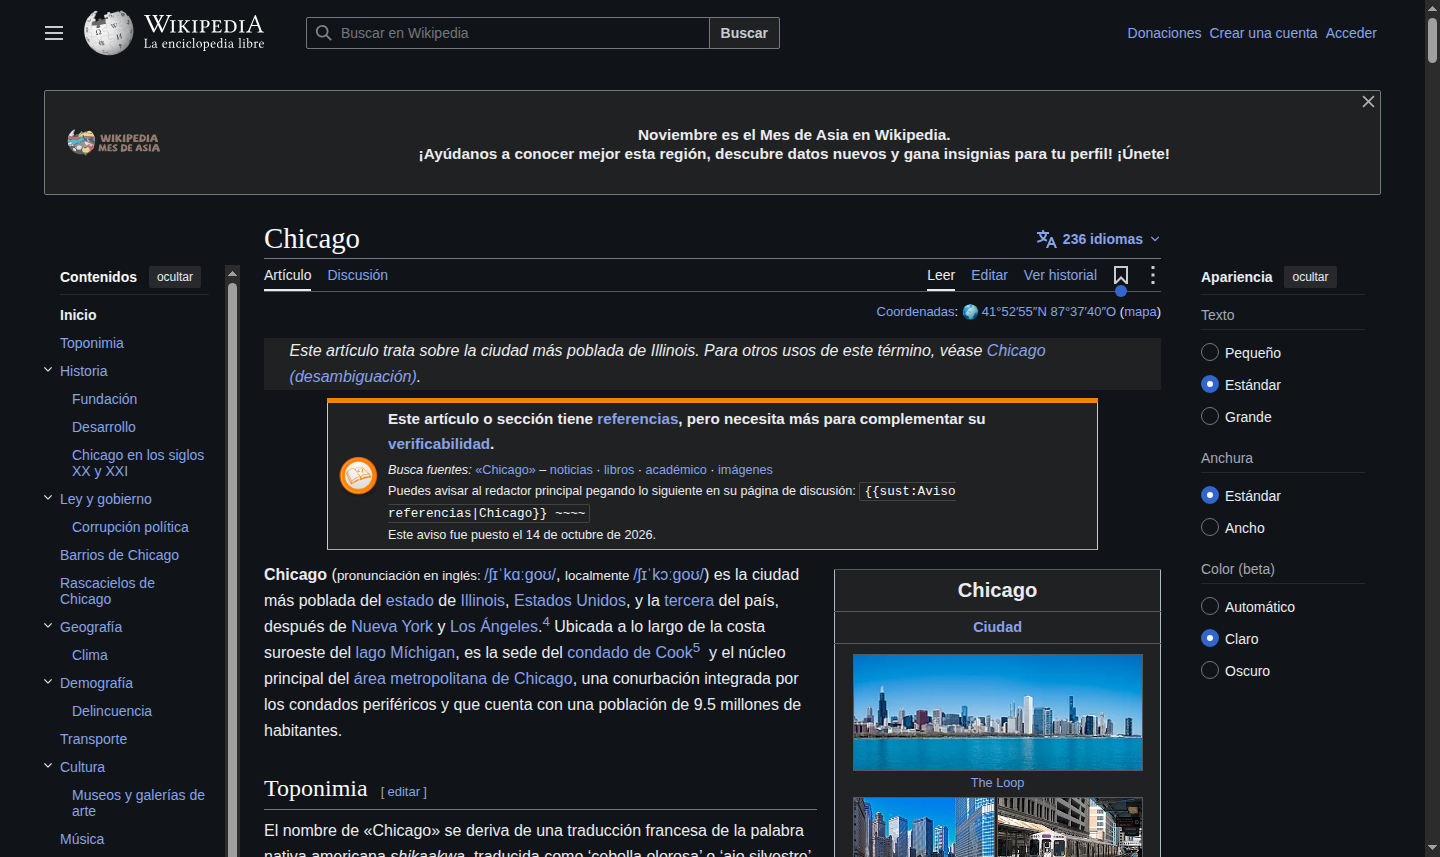


Navegador cerrado correctamente.

Proceso de documentación finalizado.


In [54]:

from pathlib import Path
import pandas as pd
from IPython.display import display, Image as IPyImage

# Organizo las carpetas de resultados y evidencias
try:
    carpeta_evidencias = Path(CARPETA_EVIDENCIAS)
except NameError:
    carpeta_evidencias = Path("evidencias_webscraping")

try:
    carpeta_salida = Path(CARPETA_SALIDA)
except NameError:
    carpeta_salida = Path("resultados_webscraping")

carpeta_evidencias.mkdir(parents=True, exist_ok=True)
carpeta_salida.mkdir(parents=True, exist_ok=True)

# Localizo las capturas que realmente se generaron
capturas = sorted(carpeta_evidencias.glob("*.png"))

# Creo el registro de evidencias a partir de los archivos existentes
registro_acciones = []

for ruta in capturas:
    nombre = ruta.stem.lower()

    if "miami" in nombre:
        descripcion = "Apertura del artículo de Miami"
    elif "chicago_busqueda" in nombre:
        descripcion = "Búsqueda interna de Chicago"
    elif "tema" in nombre:
        descripcion = "Cambio de tema de Wikipedia"
    elif "idioma" in nombre or "espanol" in nombre:
        descripcion = "Cambio de idioma de Wikipedia"
    else:
        descripcion = "Evidencia de navegación automatizada"

    registro_acciones.append({
        "archivo": ruta.name,
        "descripcion": descripcion,
        "ruta": str(ruta)
    })

# Genero la tabla y exporto el registro
df_evidencias = pd.DataFrame(
    registro_acciones,
    columns=["archivo", "descripcion", "ruta"]
)

ruta_evidencias_csv = carpeta_salida / "evidencias_selenium.csv"

df_evidencias.to_csv(
    ruta_evidencias_csv,
    index=False,
    encoding="utf-8-sig"
)

print("REGISTRO DE EVIDENCIAS")
display(df_evidencias)

print("\nCantidad de capturas:", len(capturas))
print("Archivo CSV:", ruta_evidencias_csv.resolve())

# Muestro las capturas dentro del notebook
if capturas:
    for ruta in capturas:
        print("\n", ruta.name)
        display(IPyImage(filename=str(ruta)))
else:
    print("Todavía no hay capturas guardadas.")

# Cierro el navegador al finalizar
if "driver" in globals():
    try:
        driver.quit()
        print("\nNavegador cerrado correctamente.")
    except Exception:
        print("\nEl navegador ya estaba cerrado.")

print("\nProceso de documentación finalizado.")


In [55]:
from pathlib import Path

carpetas = [
    Path("evidencias_webscraping"),
    Path("resultados_webscraping")
]

for carpeta in carpetas:
    print("\nCARPETA:", carpeta)

    if carpeta.exists():
        for archivo in sorted(carpeta.iterdir()):
            print("✅", archivo.name)
    else:
        print("⚠️ No encontrada")

# Compruebo las capturas principales
evidencias = Path("evidencias_webscraping")

esperadas = [
    "01_miami_inicio.png",
    "02_chicago_busqueda.png",
    "03_chicago_tema_cambiado.png",
    "04_chicago_idioma_espanol.png",
    "05_chicago_tema_oscuro_verificado.png"
]

print("\nCOMPROBACIÓN DE CAPTURAS")

for nombre in esperadas:
    existe = (evidencias / nombre).exists()
    print("✅" if existe else "❌", nombre, "-", existe)


CARPETA: evidencias_webscraping
✅ 01_miami_inicio.png
✅ 02_chicago_busqueda.png
✅ 03_chicago_tema_cambiado.png
✅ 04_chicago_idioma_espanol.png
✅ 05_chicago_tema_oscuro_verificado.png

CARPETA: resultados_webscraping
⚠️ No encontrada

COMPROBACIÓN DE CAPTURAS
✅ 01_miami_inicio.png - True
✅ 02_chicago_busqueda.png - True
✅ 03_chicago_tema_cambiado.png - True
✅ 04_chicago_idioma_espanol.png - True
✅ 05_chicago_tema_oscuro_verificado.png - True


In [56]:
from pathlib import Path

print("ARCHIVOS DE RESULTADOS ENCONTRADOS:\n")

# Compruebo las rutas utilizadas por el notebook
for nombre in ["ruta_resumen", "ruta_txt", "ruta_evidencias_csv"]:
    if nombre in globals():
        ruta = Path(globals()[nombre])
        print(nombre, "→", ruta, "| Existe:", ruta.exists())

# Busco los CSV y TXT generados en Colab
for extension in ["*.csv", "*.txt"]:
    for archivo in Path("/content").rglob(extension):
        if "site-packages" not in str(archivo):
            print("Encontrado:", archivo)

ARCHIVOS DE RESULTADOS ENCONTRADOS:

ruta_resumen → /content/Resultados_WebScraping/resumen_cultura_miami.csv | Existe: True
ruta_txt → /content/Resultados_WebScraping/cultura_miami_wikipedia.txt | Existe: True
ruta_evidencias_csv → /content/Resultados_WebScraping/evidencias_selenium.csv | Existe: True
Encontrado: /content/Resultados_WebScraping/cultura_miami_wikipedia.csv
Encontrado: /content/Resultados_WebScraping/evidencias_selenium.csv
Encontrado: /content/Resultados_WebScraping/resumen_cultura_miami.csv
Encontrado: /content/sample_data/california_housing_train.csv
Encontrado: /content/sample_data/mnist_test.csv
Encontrado: /content/sample_data/california_housing_test.csv
Encontrado: /content/sample_data/mnist_train_small.csv
Encontrado: /content/Resultados_WebScraping/cultura_miami_wikipedia.txt


In [57]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

# Preparo el paquete de resultados
carpetas = [
    Path("/content/Resultados_WebScraping"),
    Path("/content/evidencias_webscraping")
]

zip_salida = Path("/content/Anexos_WebScraping.zip")

with ZipFile(zip_salida, "w", ZIP_DEFLATED) as zipf:
    for carpeta in carpetas:
        if carpeta.exists():
            for archivo in carpeta.rglob("*"):
                if archivo.is_file():
                    zipf.write(
                        archivo,
                        archivo.relative_to("/content")
                    )

# Compruebo el contenido
with ZipFile(zip_salida, "r") as zipf:
    print("ARCHIVOS INCLUIDOS:")
    for nombre in zipf.namelist():
        print("✅", nombre)

print("\nPaquete creado correctamente.")

# Descargo los resultados
files.download(str(zip_salida))

ARCHIVOS INCLUIDOS:
✅ Resultados_WebScraping/cultura_miami_wikipedia.txt
✅ Resultados_WebScraping/cultura_miami_wikipedia.csv
✅ Resultados_WebScraping/evidencias_selenium.csv
✅ Resultados_WebScraping/resumen_cultura_miami.csv
✅ evidencias_webscraping/05_chicago_tema_oscuro_verificado.png
✅ evidencias_webscraping/03_chicago_tema_cambiado.png
✅ evidencias_webscraping/04_chicago_idioma_espanol.png
✅ evidencias_webscraping/02_chicago_busqueda.png
✅ evidencias_webscraping/01_miami_inicio.png

Paquete creado correctamente.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Conclusiones del avance

Con este avance incorporo una fuente pública de información cultural y aplico técnicas de extracción de datos y automatización de navegador. Al ejecutar todas las celdas, obtengo:

- Párrafos de la sección cultural del artículo de Miami, organizados por subsección.
- Archivos CSV y TXT con el contenido extraído y un resumen de la cantidad de párrafos y palabras.
- Un recorrido automatizado con Selenium desde el artículo de Miami hasta la búsqueda de Chicago.
- La modificación del tema visual y del idioma de la página, junto con capturas y un registro de las acciones realizadas.

Este trabajo complementa la información de la base de clientes y los datos de Yelp. La información cultural tiene un alcance descriptivo, por lo que la utilizo como contexto para pensar oportunidades de marketing. Para fundamentar una decisión, contrasto cualquier idea que surja de Wikipedia con los patrones reales de preferencias y consumo que identifiqué en los datos del proyecto.

**Reflexión personal:** este avance me permitió practicar la extracción automatizada de información de una página web, organizar el contenido obtenido y controlar un navegador mediante Selenium. También tuve que considerar que la estructura de una página puede cambiar, por lo que incorporé verificaciones y registro de evidencias.


## 10. Fuentes y referencias

Para realizar este avance consulté las siguientes fuentes y documentaciones:

- [Artículo de Miami — Wikipedia](https://en.wikipedia.org/wiki/Miami)
- [Artículo de Chicago — Wikipedia](https://en.wikipedia.org/wiki/Chicago)
- [Artículo de Chicago en español — Wikipedia](https://es.wikipedia.org/wiki/Chicago)
- [Política de User-Agent de Wikimedia](https://foundation.wikimedia.org/wiki/Policy:Wikimedia_Foundation_User-Agent_Policy)
- [Buenas prácticas y límites de uso de las API de Wikimedia](https://www.mediawiki.org/wiki/Wikimedia_APIs/Rate_limits)
- [Documentación oficial de Selenium para esperas explícitas](https://www.selenium.dev/documentation/webdriver/waits/)
- [Documentación oficial de Selenium para opciones del navegador](https://www.selenium.dev/documentation/webdriver/drivers/options/)
- [Manual de modo oscuro de MediaWiki](https://www.mediawiki.org/wiki/Manual:Dark_mode)

**Atribución del contenido extraído:** el contenido textual que obtengo del artículo “Miami” corresponde a Wikipedia contributors. El texto de Wikipedia está sujeto a los términos de licencia aplicables, incluidas las condiciones de atribución y de compartir bajo la misma licencia (CC BY-SA 4.0). Antes de reutilizarlo fuera de este trabajo, reviso la página de la fuente y los términos vigentes.
